# CR04b - Tree SHAP for the LightGBM challenger (LendingClub)

Goal: explain the CR02 monotone LightGBM challenger with tree SHAP. SHAP values are computed on
the raw score (log-odds of good). Negative values push an applicant toward default, so the most
negative values are the reasons for a risky score.

Checks: (1) SHAP is additive to the raw score, (2) the sign of each constrained feature's effect
agrees with its monotone constraint.

Data: LendingClub, test window 2015 to 2016 (CR02 split). A random sample of 50,000 test loans is
explained, with seed 42.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_core.datasets import LC_MONOTONE
from credit_core.models import lgbm_frame
from gbm_monotone.pipeline import fit_challenger, load_oot
from reason_codes.shap_explain import (
    additivity_error,
    challenger_shap,
    direction_agreement,
    global_importance,
)

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
SAMPLE_N = 50_000
SEED = 42

/home/patotricks15/.local/share/credit-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Challenger and sample

In [2]:
d = load_oot()
model = fit_challenger(d)
X_all = lgbm_frame(d.X_test, d.categories)
sample = X_all.sample(n=SAMPLE_N, random_state=SEED)
y_sample = d.y_test.loc[sample.index]
print(f"Explained loans: {len(sample):,}, good share: {y_sample.mean():.3f}")

Explained loans: 50,000, good share: 0.787


## 2. SHAP values and additivity check

In [3]:
values, base = challenger_shap(model, sample)
raw = model.predict(sample, raw_score=True)
err = additivity_error(values, base, raw)
print(f"Base value (log-odds of good): {base:.3f}")
print(f"Max |base + sum(SHAP) - raw score|: {err:.2e}")

/home/patotricks15/.local/share/credit-venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Base value (log-odds of good): 1.784
Max |base + sum(SHAP) - raw score|: 1.51e-14


## 3. Global importance

In [4]:
imp = global_importance(values, sample.columns)
print(imp.round(3).to_string())

term_months               0.397
fico_range_low            0.292
installment               0.239
annual_inc                0.221
dti                       0.141
inq_last_6mths            0.117
open_acc                  0.106
revol_bal                 0.096
loan_amnt                 0.077
purpose                   0.075
home_ownership            0.072
revol_util                0.059
total_acc                 0.057
emp_length_years          0.048
mort_acc                  0.046
mths_since_last_delinq    0.044
verification_status       0.037
credit_history_months     0.035
pub_rec                   0.004
delinq_2yrs               0.003


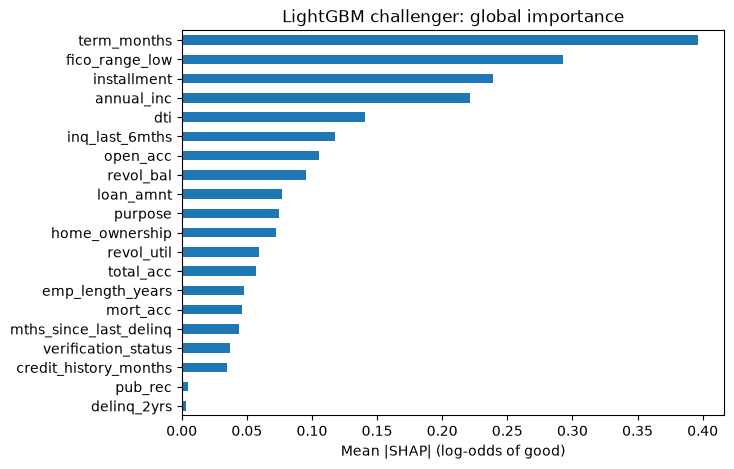

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
imp.sort_values().plot.barh(ax=ax)
ax.set(xlabel="Mean |SHAP| (log-odds of good)", title="LightGBM challenger: global importance")
fig.savefig(FIG / "cr04b_shap_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Monotone constraints vs SHAP direction

In [6]:
agree = direction_agreement(values, sample, LC_MONOTONE)
print(agree.round(3).to_string(index=False))
print(f"\nConstrained features whose SHAP direction agrees: {agree['agrees'].sum()} of {len(agree)}")

       feature  expected_sign  spearman_rho  agrees
    annual_inc              1         0.989    True
           dti             -1        -0.990    True
   delinq_2yrs             -1        -0.574    True
fico_range_low              1         0.988    True
inq_last_6mths             -1        -0.872    True
       pub_rec             -1        -0.676    True
    revol_util             -1        -0.980    True

Constrained features whose SHAP direction agrees: 7 of 7


## 5. Reasons for one risky applicant

Take a defaulted loan with a low predicted good score. Its top-3 reasons are the three features
with the most negative SHAP values.

In [7]:
p_good = model.predict_proba(sample)[:, 1]
cand = pd.DataFrame({"p_good": p_good, "y": y_sample.to_numpy()}, index=sample.index)
pick = cand[cand["y"] == 0].nsmallest(1, "p_good").index[0]
row = sample.index.get_loc(pick)
contrib = pd.Series(values[row], index=sample.columns)
top3 = contrib.nsmallest(3)
print(f"Loan index {pick}: predicted good {p_good[row]:.3f}, observed default")
print("Top-3 reasons (most negative SHAP):")
print(top3.round(3).to_string())

Loan index 81071: predicted good 0.246, observed default
Top-3 reasons (most negative SHAP):
revol_bal     -0.743
term_months   -0.742
annual_inc    -0.345


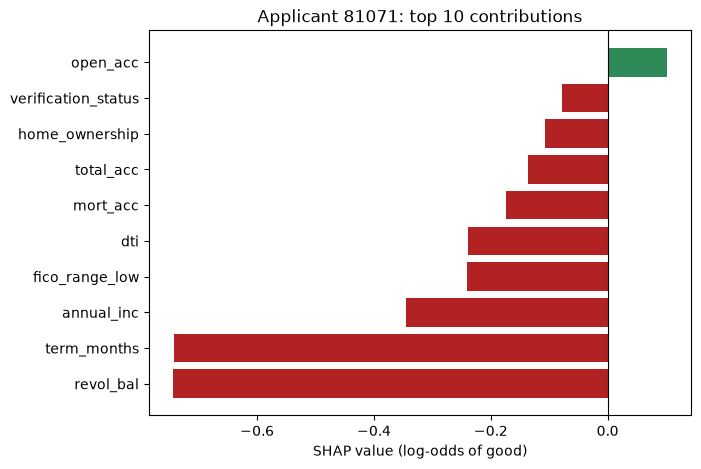

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
show = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:10]).sort_values()
colors = ["firebrick" if v < 0 else "seagreen" for v in show]
ax.barh(show.index, show.to_numpy(), color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="SHAP value (log-odds of good)", title=f"Applicant {pick}: top 10 contributions")
fig.savefig(FIG / "cr04b_applicant_shap.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Summary

In [9]:
print(f"Additivity error: {err:.2e}")
print(f"Constrained features agreeing with SHAP: {agree['agrees'].sum()} of {len(agree)}")
print(imp.head(3).round(3).to_string())

Additivity error: 1.51e-14
Constrained features agreeing with SHAP: 7 of 7
term_months       0.397
fico_range_low    0.292
installment       0.239
